# Exploratory Data Analysis — ATUS 2023

**CRISP-DM Phase 2: Data Understanding** for the slot recommender.

Goal: understand the American Time Use Survey (ATUS) 2023 data before engineering features, so that the
choices made in Data Preparation (Sprint 2) are backed by evidence.

Questions answered:
1. How big is the data and how is it structured?
2. Are there missing or invalid values?
3. How do ATUS activities spread across the six Wasaa categories?
4. At what hours, on which days and for how long do people do each category?
5. How many activities does a person record in a day (schedule density)?
6. What does this mean for labels, splits and leakage?

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

sys.path.append(str(Path("..") / "src"))
from atus_category_map import CATEGORIES, map_activity_category

RAW = Path("..") / "data" / "raw"
pd.set_option("display.max_columns", 40)

## 1. Load the data

- **Activity file**: one row per activity a respondent did during their diary day.
- **Respondent file**: one row per respondent. Only the columns needed here are loaded:
  `TUDIARYDAY` (1 = Sunday … 7 = Saturday), `TRHOLIDAY` (diary day was a holiday) and `TUFINLWGT` (survey weight).

In [2]:
act = pd.read_csv(RAW / "atusact_2023.dat")
resp = pd.read_csv(RAW / "atusresp_2023.dat", usecols=["TUCASEID", "TUDIARYDAY", "TRHOLIDAY", "TUFINLWGT"])

print(f"Activity rows:   {len(act):,}  ({act.shape[1]} columns)")
print(f"Respondent rows: {len(resp):,}")
print(f"Respondents with activities: {act['TUCASEID'].nunique():,}")
act.head()

Activity rows:   153,120  (30 columns)
Respondent rows: 8,548
Respondents with activities: 8,548


,TUCASEID,TUACTIVITY_N,TEWHERE,TRTCCTOT_LN,TRTCC_LN,TRTCOC_LN,TRTEC_LN,TRTHH_LN,TRTNOHH_LN,TRTOHH_LN,TRTONHH_LN,TRTO_LN,TUACTDUR,TUACTDUR24,TUCC5,TUCC5B,TUCC7,TUCC8,TUCUMDUR,TUCUMDUR24,TUDURSTOP,TUEC24,TUSTARTTIM,TUSTOPTIME,TUTIER1CODE,TUTIER2CODE,TUTIER3CODE,TRCODE,TRTIER2,TXWHERE
0,20230101230035,1,-1,0,-1,0,-1,-1,-1,-1,-1,-1,240,240,0,0,0,97,240,240,2,-1,04:00:00,08:00:00,1,1,1,10101,101,0
1,20230101230035,2,12,0,-1,0,-1,-1,-1,-1,-1,-1,20,20,0,0,0,0,260,260,1,-1,08:00:00,08:20:00,18,13,1,181301,1813,0
2,20230101230035,3,31,0,-1,0,-1,-1,-1,-1,-1,-1,120,120,0,0,0,0,380,380,1,-1,08:20:00,10:20:00,13,1,33,130133,1301,0
3,20230101230035,4,12,0,-1,0,-1,-1,-1,-1,-1,-1,20,20,0,0,0,0,400,400,1,-1,10:20:00,10:40:00,18,13,1,181301,1813,0
4,20230101230035,5,1,0,-1,0,-1,-1,-1,-1,-1,-1,10,10,0,0,0,0,410,410,1,-1,10:40:00,10:50:00,2,2,1,20201,202,0


## 2. Data quality

ATUS does not use empty cells for missing data. It uses **negative codes**: `-1` blank / not applicable,
`-2` don't know, `-3` refused. So both real nulls and negative values are checked for the columns the model will use.

In [3]:
key_cols = ["TUCASEID", "TUSTARTTIM", "TUACTDUR24", "TUTIER1CODE", "TUTIER2CODE"]

quality = pd.DataFrame({
    "nulls": act[key_cols].isna().sum(),
    "negative_codes": (act[["TUACTDUR24", "TUTIER1CODE", "TUTIER2CODE"]] < 0).sum(),
}).fillna(0).astype(int)
print(quality)

print(f"\nDuplicate activity rows: {act.duplicated().sum():,}")
print(f"Respondents missing a diary day: {resp['TUDIARYDAY'].isna().sum():,}")
print(f"Activities with zero duration: {(act['TUACTDUR24'] == 0).sum():,}")

             nulls  negative_codes
TUACTDUR24       0               0
TUCASEID         0               0
TUSTARTTIM       0               0
TUTIER1CODE      0               0
TUTIER2CODE      0               0

Duplicate activity rows: 0
Respondents missing a diary day: 0
Activities with zero duration: 0


## 3. Mapping activities to Wasaa categories

Uses `src/atus_category_map.py` (issue #8). Codes that do not fit a category (e.g. `50` "unable to code")
map to `None` and will be dropped.

Excluded (no category): 1,600 rows (1.04%)
           rows  share
category              
work       7095  0.047
exercise   2600  0.017
leisure   38858  0.256
errand    57743  0.381
social    14482  0.096
rest      30742  0.203


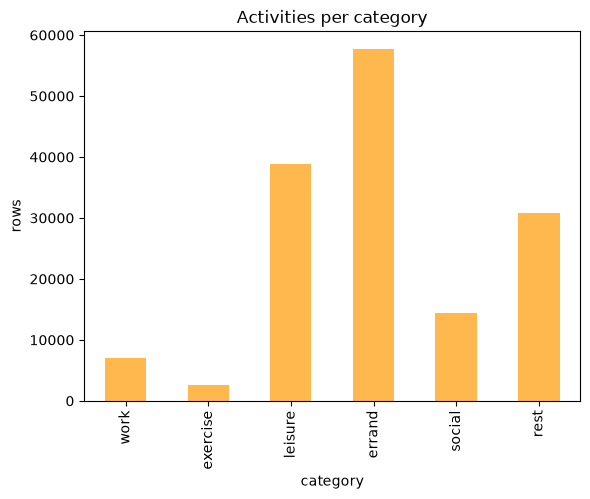

In [4]:
pairs = act[["TUTIER1CODE", "TUTIER2CODE"]].drop_duplicates()
pairs["category"] = [map_activity_category(t1, t2) for t1, t2 in zip(pairs["TUTIER1CODE"], pairs["TUTIER2CODE"])]
df = act.merge(pairs, on=["TUTIER1CODE", "TUTIER2CODE"], how="left")

excluded = df["category"].isna().sum()
print(f"Excluded (no category): {excluded:,} rows ({excluded / len(df):.2%})")

df = df.dropna(subset=["category"]).copy()
counts = df["category"].value_counts().reindex(CATEGORIES)
print(pd.DataFrame({"rows": counts, "share": (counts / counts.sum()).round(3)}))

counts.plot(kind="bar", color="#ffb84d", title="Activities per category")
plt.ylabel("rows")
plt.show()

### 3b. What is inside the two largest categories?

`errand` and `rest` together hold most rows. Two mapping effects are checked:
- **Travel (tier-1 `18`) is mapped to errand**, and ATUS records a travel episode between almost every activity.
- **Sleep at 04:00**: the diary day starts at 04:00, so anyone asleep at that moment gets an activity that "starts" at 04:00.

In [5]:
errand = df[df["category"] == "errand"]
travel = (errand["TUTIER1CODE"] == 18).sum()
print(f"Errand rows that are travel: {travel:,} of {len(errand):,} ({travel / len(errand):.1%})")

rest = df[df["category"] == "rest"]
at_four = (rest["TUSTARTTIM"] == "04:00:00").sum()
print(f"Rest rows starting exactly at 04:00: {at_four:,} of {len(rest):,} ({at_four / len(rest):.1%})")

work_time = df.loc[df["category"] == "work", "TUACTDUR24"].sum() / df["TUACTDUR24"].sum()
print(f"Work: {counts['work'] / counts.sum():.1%} of rows but {work_time:.1%} of recorded minutes")

Errand rows that are travel: 25,041 of 57,743 (43.4%)
Rest rows starting exactly at 04:00: 8,057 of 30,742 (26.2%)
Work: 4.7% of rows but 10.9% of recorded minutes


## 4. When do people do each category? (start hour)

Each row is normalised **within its category**, so the colours show at which hours that category is most common,
regardless of how big the category is. This is the core pattern the model has to learn.

Note: an ATUS diary day runs from **04:00 to 04:00** the next morning.

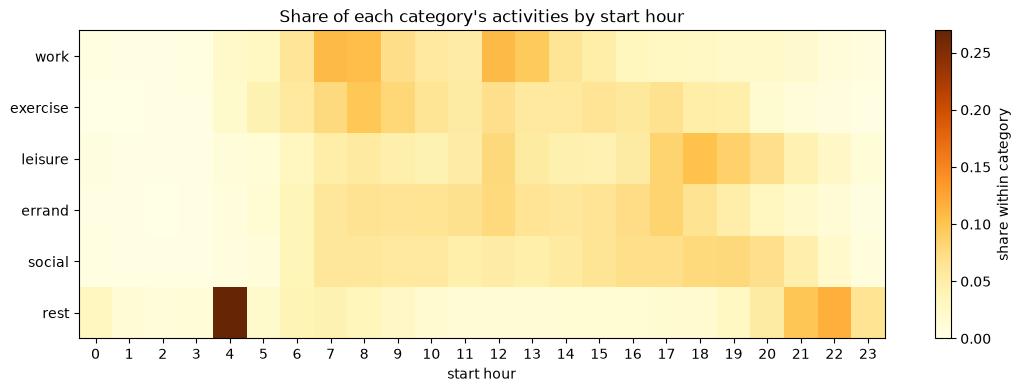

Peak hour per category:
category
work        12
exercise     8
leisure     18
errand      17
social      19
rest         4
dtype: int64


In [6]:
df["hour"] = df["TUSTARTTIM"].str.slice(0, 2).astype(int)

share = pd.crosstab(df["category"], df["hour"], normalize="index").reindex(CATEGORIES)

fig, ax = plt.subplots(figsize=(13, 4))
im = ax.imshow(share, aspect="auto", cmap="YlOrBr")
ax.set_yticks(range(len(share.index)), share.index)
ax.set_xticks(range(24))
ax.set_xlabel("start hour")
ax.set_title("Share of each category's activities by start hour")
fig.colorbar(im, label="share within category")
plt.show()

print("Peak hour per category:")
print(share.idxmax(axis=1))

## 5. Which days? (day of week)

Each respondent reports **one** diary day. ATUS deliberately samples weekends more heavily, so raw counts are
not the same as how the population spreads its time. The survey weight `TUFINLWGT` corrects for this.

In [7]:
day_names = {1: "Sun", 2: "Mon", 3: "Tue", 4: "Wed", 5: "Thu", 6: "Fri", 7: "Sat"}
days = resp["TUDIARYDAY"].map(day_names)

by_day = pd.DataFrame({
    "respondents": days.value_counts(),
    "share": days.value_counts(normalize=True).round(3),
    "weighted_share": (resp.groupby(days)["TUFINLWGT"].sum() / resp["TUFINLWGT"].sum()).round(3),
}).reindex(list(day_names.values()))
print(by_day)
print(f"\nDiary days that were holidays: {resp['TRHOLIDAY'].eq(1).sum():,}")

df = df.merge(resp[["TUCASEID", "TUDIARYDAY"]], on="TUCASEID", how="left")
cat_by_day = pd.crosstab(df["category"], df["TUDIARYDAY"].map(day_names), normalize="columns")
print("\nCategory mix per day:")
print(cat_by_day.reindex(index=CATEGORIES, columns=list(day_names.values())).round(3))

            respondents  share  weighted_share
TUDIARYDAY                                    
Sun                2148  0.251           0.143
Mon                 904  0.106           0.139
Tue                 914  0.107           0.142
Wed                 833  0.097           0.150
Thu                 866  0.101           0.139
Fri                 849  0.099           0.142
Sat                2034  0.238           0.144

Diary days that were holidays: 139

Category mix per day:
TUDIARYDAY    Sun    Mon    Tue    Wed    Thu    Fri    Sat
category                                                   
work        0.021  0.066  0.070  0.074  0.076  0.062  0.022
exercise    0.016  0.018  0.018  0.018  0.018  0.017  0.017
leisure     0.274  0.255  0.245  0.240  0.240  0.241  0.266
errand      0.375  0.364  0.366  0.374  0.380  0.395  0.400
social      0.103  0.094  0.100  0.098  0.084  0.090  0.094
rest        0.212  0.204  0.201  0.196  0.202  0.195  0.201


## 6. How long? (duration in minutes)

`TUACTDUR24` is the duration cut off at the end of the diary day (04:00), which matters for long activities like sleep.

            count   mean    std  min   25%    50%    75%     max
category                                                        
work       7095.0  187.1  135.3  1.0  90.0  165.0  250.0  1080.0
exercise   2600.0   69.8   73.9  1.0  30.0   50.0   90.0   840.0
leisure   38858.0   76.4   83.3  1.0  30.0   50.0  102.0  1120.0
errand    57743.0   32.9   46.7  1.0  10.0   20.0   30.0   840.0
social    14482.0   54.3   69.0  1.0  15.0   30.0   60.0  1005.0
rest      30742.0  164.3  146.6  1.0  30.0  120.0  300.0  1080.0


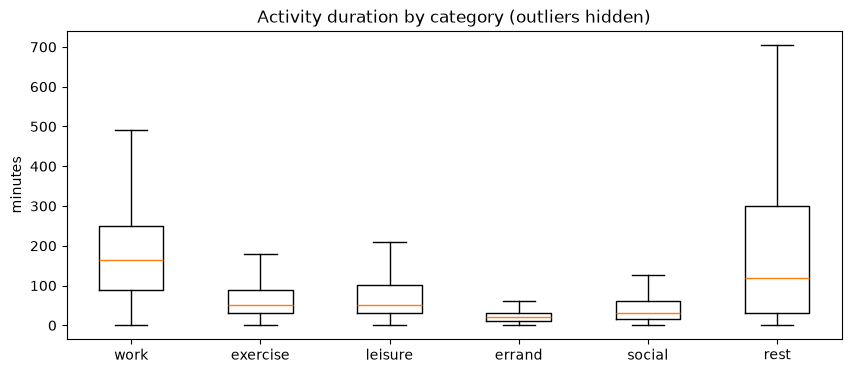

In [8]:
print(df.groupby("category")["TUACTDUR24"].describe().reindex(CATEGORIES).round(1))

fig, ax = plt.subplots(figsize=(10, 4))
ax.boxplot([df.loc[df["category"] == c, "TUACTDUR24"] for c in CATEGORIES], showfliers=False)
ax.set_xticks(range(1, len(CATEGORIES) + 1), CATEGORIES)
ax.set_ylabel("minutes")
ax.set_title("Activity duration by category (outliers hidden)")
plt.show()

## 7. Schedule density (activities per person per day)

This becomes the *schedule density* feature: how busy the day already is.

count    8548.0
mean       17.7
std         7.3
min         4.0
25%        12.0
50%        17.0
75%        22.0
max        67.0
dtype: float64


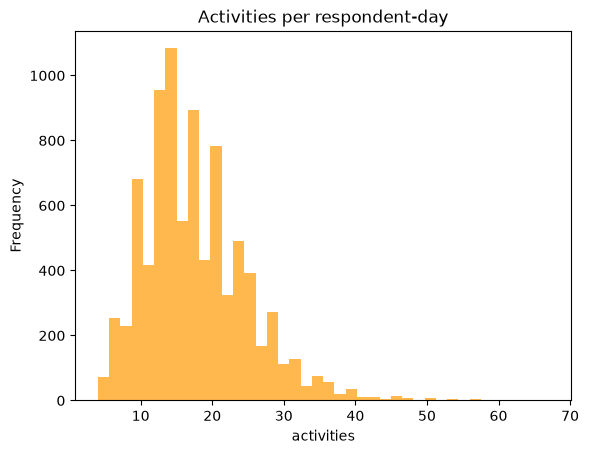

In [9]:
per_person = df.groupby("TUCASEID").size()
print(per_person.describe().round(1))

per_person.plot(kind="hist", bins=40, color="#ffb84d", title="Activities per respondent-day")
plt.xlabel("activities")
plt.show()

## 8. Findings and implications for Data Preparation

**Data size and quality**
- 153,120 activity rows from 8,548 respondents (one diary day each), 30 columns.
- No nulls, no negative codes, no duplicates and no zero durations in the columns used. Little cleaning is needed.
- 1,600 rows (1.04%) have no Wasaa category (data code `50`) and are dropped.

**Category distribution**
| category | rows | share |
|---|---|---|
| errand | 57,743 | 38.1% |
| leisure | 38,858 | 25.6% |
| rest | 30,742 | 20.3% |
| social | 14,482 | 9.6% |
| work | 7,095 | 4.7% |
| exercise | 2,600 | 1.7% |

**Timing patterns** (peak start hour): exercise 08:00, work 12:00, errand 17:00, leisure 18:00, social 19:00, rest 04:00.
Categories clearly differ by time of day, which supports hour as a key feature.

**Implications**
1. **Only positive examples.** ATUS records what people *did*. There are no "not suitable" slots, so negatives must be
   generated in Data Preparation. The label is a proxy and is reported as a limitation.
2. **Leakage risk.** Each respondent contributes about 18 rows. The train/validation/test split must be **grouped by
   `TUCASEID`** so no person appears in more than one set.
3. **Completion rate from training data only.** The category-by-hour frequency must be computed on the training set
   and then applied to validation and test.
4. **Travel inflates errand.** About 43% of errand rows are travel (tier-1 `18`). Travel sits between activities and is not
   usually something a user schedules. Candidate change: exclude travel. To be decided and justified in Data Preparation.
5. **04:00 is an artefact for rest.** 8,057 rest rows (26.2%) "start" at exactly 04:00 only because the diary day begins then while
   people are asleep. These start times do not reflect a chosen time and should be excluded or handled when learning start hours.
6. **Weekend oversampling.** Sat and Sun are 49% of respondents but 29% after survey weighting. Work drops from about 7%
   of weekday rows to 2% at weekends, so day of week is informative, and evaluation should be read with this in mind.
7. **Category imbalance.** Exercise has only 2,600 rows and work 4.7% of rows (but 10.9% of recorded minutes, since work episodes are long).
   Results must be reported per category, not just overall.
8. **Schedule density.** Mean 17.7 and median 17 activities per person-day (range 4–67). Usable directly as a feature.